In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from sklearn.datasets import load_diabetes
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [4]:
X, Y = make_regression(n_samples = 100, n_features = 2, n_informative = 2, n_targets = 1, noise = 50)

In [6]:
df = pd.DataFrame({'feature1':X[:, 0], 'feature2':X[:, 1], 'target':Y})
df.head(2)

,feature1,feature2,target
0,0.350799,0.002336,58.370421
1,-1.296456,0.165234,7.189788


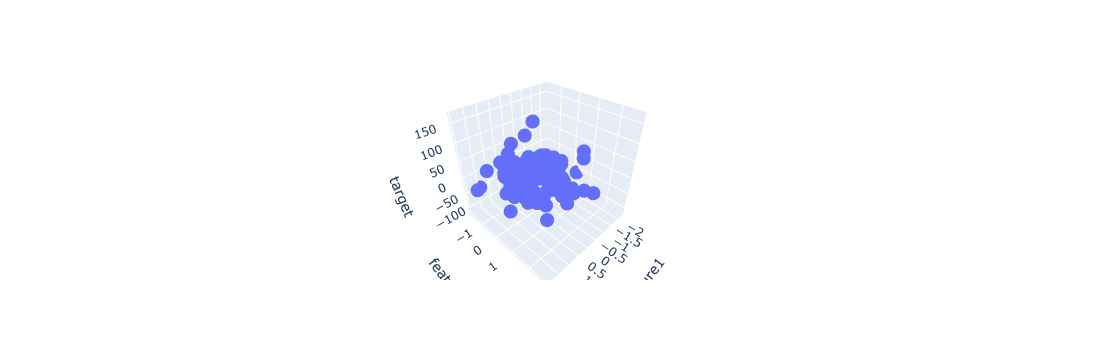

In [9]:
fig = px.scatter_3d(df, x='feature1', y='feature2', z= 'target')
fig.show()

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 2)

In [11]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[29.7 ,20.98]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.751
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2,)","[8.58,7.41]"


In [34]:
Y_pred = lr.predict(X_test)

print('r2 score is', r2_score(Y_test, Y_pred))
print('MAE is', mean_absolute_error(Y_test, Y_pred))
print('MSE is', mean_squared_error(Y_test, Y_pred))

r2 score is -0.24431063075915005
MAE is 34.38100484317853
MSE is 1848.979631334893


In [13]:
lr.coef_           ### beta1 and beta2 values

array([29.70373713, 20.97799368])

In [14]:
lr.intercept_  

np.float64(-2.7514148368071036)

In [17]:

x = np.linspace(-5, 5, 10)
y = np.linspace(-5, 5, 10)
xGrid, yGrid = np.meshgrid(x, y)                       # x first, then y

final = np.c_[xGrid.ravel(), yGrid.ravel()]            # shape (100, 2): one row per grid point

z = lr.predict(final).reshape(xGrid.shape)             # back to a 10 x 10 grid

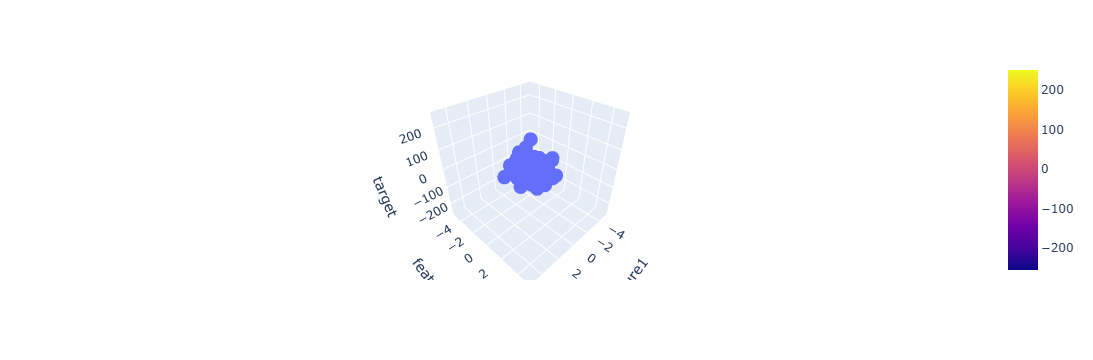

In [18]:

fig = px.scatter_3d(df, x='feature1', y='feature2', z='target')

fig.add_trace(go.Surface(x = x, y = y, z =z ))

fig.show()

In [28]:
X1, Y1 = load_diabetes(return_X_y=True)

X1

array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
         0.01990749, -0.01764613],
       [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
        -0.06833155, -0.09220405],
       [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
         0.00286131, -0.02593034],
       ...,
       [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
        -0.04688253,  0.01549073],
       [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
         0.04452873, -0.02593034],
       [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
        -0.00422151,  0.00306441]], shape=(442, 10))

In [26]:
X1.shape

(442, 10)

In [29]:
from sklearn.model_selection import train_test_split

X_train1, X_test1, Y_train1, Y_test1 = train_test_split(X1, Y1, test_size = 0.2, random_state = 2)

In [32]:
X_train1.shape

(353, 10)

In [30]:
from sklearn.linear_model import LinearRegression

lr1 = LinearRegression()

lr1.fit(X_train1, Y_train1)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ -9.16,-205.45, 516.69,..., 126.73, 861.13, 52.42]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,151.9
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[1.79,1.1 ,0.98,...,0.58,0.24,0.08]"


In [33]:
Y_pred1 = lr1.predict(X_test1)

print('r2 score is', r2_score(Y_test1, Y_pred1))
print('MAE is', mean_absolute_error(Y_test1, Y_pred1))
print('MSE is', mean_squared_error(Y_test1, Y_pred1))

r2 score is 0.4399338661568968
MAE is 45.213034190469024
MSE is 3094.4566715660626


In [35]:
lr1.coef_

array([  -9.15865318, -205.45432163,  516.69374454,  340.61999905,
       -895.5520019 ,  561.22067904,  153.89310954,  126.73139688,
        861.12700152,   52.42112238])

In [37]:
lr1.intercept_

np.float64(151.88331005254167)

In [89]:
###  own class


class linreg():

    def __init__(self):
        self.coef_= None
        self.intercept_= None

    def fit(self, X_train1, Y_train1):
        X_train1 = np.insert(X_train1, 0, 1, axis=1)

        # calculate the coeff

        betas = np.linalg.inv(np.dot(X_train1.T, X_train1)).dot(X_train1.T).dot(Y_train1)
        self.intercept_ = betas[0]
        self.coef_ = betas[1:]
        print(betas)

    def predict(self, X_test1):
        Y_pred1 = np.dot(X_test1, self.coef_) + self.intercept_
        return Y_pred1


In [87]:
Lr = linreg()

In [90]:
Lr.fit(X_train1, Y_train1)

[ 151.88331005   -9.15865318 -205.45432163  516.69374454  340.61999905
 -895.5520019   561.22067904  153.89310954  126.73139688  861.12700152
   52.42112238]


In [85]:
X_train1.shape

(353, 10)

In [91]:
Y_pred1 = Lr.predict(X_test1)

[154.1213881  204.81835118 124.93755353 106.08950893 258.5348576
 256.3310074  118.75087616 119.52440696 101.50816735 190.54048661
 141.70656811 172.51883961 174.33861649 134.80942706 294.13994537
  94.11798038 211.97059795 156.49579378 134.21000428 119.62664644
 148.87842251 165.00873409 151.10021038 176.04063756 133.27769647
 221.29555392 197.17324941  96.1577688   50.26012711 230.48580317
 242.06073866 114.11129218  67.07532417  94.52943825 201.21415375
 167.05136201 159.881268   192.78746659 114.49551325 233.48234551
 140.82563045 121.0680409  192.27480772 191.12738845 179.16865788
 148.34935601 163.47414622 276.81647884 100.17926432 164.10555298
 255.80762189 136.9466204  152.37503699 107.92237882 194.21924678
  77.34670792 118.50482479  68.38335763 154.29258529 162.48840259
 168.36788326 156.87790322  97.14191797 238.1671215  145.46179904
 117.65702433 168.88784311 198.38683887 118.24053714 124.64552812
 223.17700368 200.63012386 129.54414666 158.1584765  154.332565
 114.47070769

In [95]:
###  own class


class linreg():

    def __init__(self):
        self.coef_= None
        self.intercept_= None

    def fit(self, X_train1, Y_train1):
        X_train1 = np.insert(X_train1, 0, 1, axis=1)

        # calculate the coeff  ---  beta = (X-tanspose X)-1 (X -transpose) * Y  -- its all dot product

        betas = np.linalg.inv(np.dot(X_train1.T, X_train1)).dot(X_train1.T).dot(Y_train1)
        self.intercept_ = betas[0]
        self.coef_ = betas[1:]
        print(betas)

    def predict(self, X_test1):
        Y_pred1 = np.dot(X_test1, self.coef_) + self.intercept_
        return Y_pred1

l_1 = linreg()
l_1.fit(X_train1, Y_train1)

Y_pred1 = l_1.predict(X_test1)

print(type(Y_pred1), Y_pred1[:5])

print('r2 score is', r2_score(Y_test1, Y_pred1))

[ 151.88331005   -9.15865318 -205.45432163  516.69374454  340.61999905
 -895.5520019   561.22067904  153.89310954  126.73139688  861.12700152
   52.42112238]
<class 'numpy.ndarray'> [154.1213881  204.81835118 124.93755353 106.08950893 258.5348576 ]
r2 score is 0.4399338661568968


In [96]:
from sklearn.linear_model import LinearRegression
sk = LinearRegression().fit(X_train1, Y_train1)
print(sk.intercept_, Lr.intercept_)                       # should be the same
print(r2_score(Y_test1, sk.predict(X_test1)))             # should also be 0.4399…

151.88331005254167 151.88331005254176
0.4399338661568968


In [99]:
class xyz():

    def __init__(self):

        self.coef_ = None
        self.intercept_ = None

    def fit(self, X_train1, Y_train1):

        X_train1 = np.insert(X_train1, 0, 1, axis = 1)
        betas = np.linalg.inv(np.dot(X_train1.T, X_train1)).dot(X_train1.T).dot(Y_train1)
        self.coef_ = betas[1:]
        self.intercept_ = betas[0]
        print(betas)

    def predict(self, X_test1):

        Y_pred1 = np.dot(X_test1, self.coef_) + self.intercept_
        return(Y_pred1)
        
l_2 = xyz()
l_2.fit(X_train1, Y_train1)

Y_pred1 = l_2.predict(X_test1)
print('r2', r2_score(Y_test1, Y_pred1))
        

[ 151.88331005   -9.15865318 -205.45432163  516.69374454  340.61999905
 -895.5520019   561.22067904  153.89310954  126.73139688  861.12700152
   52.42112238]
r2 0.4399338661568968
